# 06: Where we stand, and three experiments to test it

**Part A** answers two questions with the validated solver:
1. How many orders of magnitude separate us from the goal (1 W/cm³ at rest), under each set of assumptions?
2. What does a closer, lighter configuration do, and what spacing is actually needed?

**Part B** designs three experiments that the earlier notebooks point to. Each has a hypothesis, model predictions, a setup, a computed sensitivity, controls and a decision rule.

| | Experiment | What it decides |
|---|---|---|
| E1 | Gamma search for p+d fusion in H/D co-loaded Pd at rest | Does the screening anomaly act on deuterons *at rest* far enough out to matter? |
| E2 | Beam screening in a deuterium-implanted heavy-fermion compound, with a temperature switch | Is the anomaly a "heavy electron" effect? |
| E3 | p+d and d+d screening on the same target in the same run | Electron screening vs depth-profile artifact vs nuclear (threshold) resonance |

**All detector backgrounds, efficiencies and beam parameters below are stated assumptions** (typical published values, not quotes for specific hardware). Every one is a named variable, so the designs can be re-run with real numbers.

In [1]:
import numpy as np, matplotlib.pyplot as plt
from scipy import optimize
from cfsolve import *
plt.rcParams.update({"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,
                     "grid.alpha":.25,"font.size":10,"axes.titlesize":11})
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, INK, MUTED = "#2a78d6","#eb6834","#1baf7a","#eda100","#e87ba4","#0b0b0b","#52514e"
need = lambda Q: np.log10(5.6e-11*3.65/Q)          # per-pair rate for 1 W/cm^3 in PdD
LOG_LIMIT = np.log10(2e-26)
FUELS = {"pp": (4.01e-22, 1.44), "pd": (2.0e-4, 5.49), "pt": (9.5e-4, 19.81), "dd": (S_KEVB, 3.65), "dt": (1.14e4, 17.59)}

# Part A
## A1. How far from the goal?

In [2]:
goal = need(3.65)
lat_dd = solve(V_lattice(), 12.0, Rmin_well=1.0)["log10_rate"]
mol_dd = solve(V_molecule(), 8.0, Rmin_well=0.5)["log10_rate"]
lat_pd = solve(V_lattice_pair("p","d"), 12.0, Rmin_well=1.0, mu=reduced_mass("p","d"), S_keVb=2e-4)["log10_rate"]
rows = [
 ("d+d, deuterons where they sit in PdD (2.75 A), no new physics", lat_dd, goal),
 ("d+d in a D2 molecule (0.74 A), Koonin-Nauenberg case", mol_dd, goal),
 ("p+d in a co-loaded lattice, no new physics", lat_pd, need(5.49)),
 ("d+d with the measured screening, as far as neutron data allow", LOG_LIMIT, goal),
 ("p+d with the measured screening, best case on the band (x_D=0.5; notebook 05)", -12.9, need(5.49)),
]
for name, have, want in rows:
    print(f"{want-have:6.1f} orders short   {name}  (10^{have:.1f} vs 10^{want:.1f})")

 113.7 orders short   d+d, deuterons where they sit in PdD (2.75 A), no new physics  (10^-123.9 vs 10^-10.3)
  53.4 orders short   d+d in a D2 molecule (0.74 A), Koonin-Nauenberg case  (10^-63.7 vs 10^-10.3)
  96.9 orders short   p+d in a co-loaded lattice, no new physics  (10^-107.3 vs 10^-10.4)
  15.4 orders short   d+d with the measured screening, as far as neutron data allow  (10^-25.7 vs 10^-10.3)
   2.5 orders short   p+d with the measured screening, best case on the band (x_D=0.5; notebook 05)  (10^-12.9 vs 10^-10.4)


**So the answer depends on what you allow:**
* **With no new physics, about 114 orders** for deuterons where they actually sit in PdD. The "53 orders" from notebook 01 was against a D₂ molecule, which is far more favourable than the lattice.
* **With the measured screening anomaly, still ~15 orders short:** the highest d+d rate at rest that the neutron data allow (2×10⁻²⁶ s⁻¹) is 15.4 orders below watt level.
* **The nearest case is ~2.5 orders short:** p+d at the strongest measured screening, with a 50/50 H/D mix. But that would emit ~10¹² gammas per second per watt, which nobody has reported.

## A2. Closer and lighter: what spacing is needed?

In [3]:
ms = np.concatenate([np.linspace(1, 3, 9), np.linspace(3.5, 30, 30), np.logspace(np.log10(32), np.log10(210), 20)])
scan = {}
for k, (S, Q) in FUELS.items():
    scan[k] = np.array([solve(V_molecule(m), 8.0/m, Rmin_well=0.5/m, mu=reduced_mass(k[0], k[1]), S_keVb=S)["log10_rate"] for m in ms])
def cross(lr, t):
    return np.nan if lr.max() < t else optimize.brentq(lambda m: np.interp(m, ms, lr) - t, 1, ms[-1])
print(f"{'pair':5s} {'compression for 1 W':>20s} {'pair spacing':>13s} {'rate at muon-like compression':>31s}")
for k, (S, Q) in FUELS.items():
    mw = cross(scan[k], need(Q))
    sp = f"{0.741/mw*100:6.2f} pm" if np.isfinite(mw) else "   never  "
    print(f"{k:5s} {('x%.2f' % mw) if np.isfinite(mw) else 'not reached':>20s} {sp:>13s} {'10^%.1f /s' % scan[k][-1]:>31s}")

pair   compression for 1 W  pair spacing   rate at muon-like compression
pp             not reached       never                       10^-10.5 /s
pd                  x10.11       7.33 pm                       10^6.7 /s
pt                  x10.05       7.38 pm                       10^7.2 /s
dd                   x9.22       8.03 pm                      10^11.6 /s
dt                   x9.01       8.22 pm                      10^13.2 /s


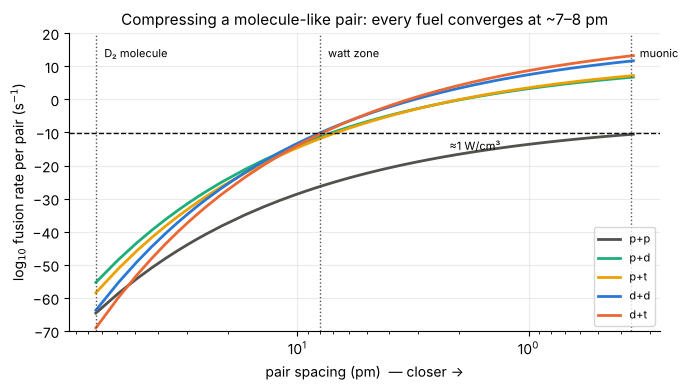

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
cols = {"pp": MUTED, "pd": AQUA, "pt": YELLOW, "dd": BLUE, "dt": ORANGE}
for k in FUELS:
    ax.plot(0.741/ms*100, scan[k], color=cols[k], lw=2, label=f"{k[0]}+{k[1]}")
ax.axhline(need(3.65), color=INK, ls="--", lw=1); ax.text(2.2, need(3.65)-5, "≈1 W/cm³", fontsize=8)
for x, lab in [(74.1, "D₂ molecule"), (8.0, "watt zone"), (0.36, "muonic")]:
    ax.axvline(x, color=MUTED, ls=":", lw=1); ax.text(x*0.92, 16, lab, fontsize=8, ha="left", va="top")
ax.set_xscale("log"); ax.invert_xaxis(); ax.set_ylim(-70, 20)
ax.set_xlabel("pair spacing (pm)  — closer →"); ax.set_ylabel("log$_{10}$ fusion rate per pair (s$^{-1}$)")
ax.set_title("Compressing a molecule-like pair: every fuel converges at ~7–8 pm")
ax.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.savefig("../figures/06_closer_lighter.png", dpi=130); plt.show()

**What "closer, lighter" does:**
* **Closer is the lever. Lighter is a modifier.** Every fuel except p+p reaches watt level at a pair spacing of **~7–8 pm (0.07–0.08 Å)**, about 9–10× tighter than a D₂ molecule and ~35× tighter than the deuteron spacing in PdD.
* **Lighter pairs help most when far apart.** At molecular spacing p+d leads d+d by 8 orders. Near the watt zone the larger nuclear factors catch up, and d+d and d+t need slightly *less* compression than p+d.
* **p+p never gets there.** Its weak-interaction nuclear factor (10⁻²⁴ of d+d) can't be made up by compression short of muonic scales.
* **At muonic compression (0.36 pm)** rates are 10⁷–10¹³ s⁻¹. That's why muon-catalyzed fusion works, and why its problem is economics, not physics.

**The target any mechanism has to hit:** hold hydrogen-isotope pairs at ≤ 8 pm (or produce the equivalent close-range probability) at rest. Nothing in the measured data does this. The experiments below test the three places where something *could* still be hiding.

# Part B: Experiment designs

## E1. Gamma search for p+d fusion in H/D co-loaded palladium at rest

**Hypothesis tested:** the beam-measured screening (165–575 eV) extends far enough at rest to raise the p+d rate (notebook 05 §3). p+d → ³He + **5.49 MeV γ** has no neutron branch, so the 1990 neutron searches never tested it.

**Setup:**
* Pd foil, electrochemically co-loaded with H and D from a mixed H₂O/D₂O electrolyte to (H+D)/Pd ≈ 0.9. Loading is monitored in situ by the resistance ratio. Run steady loading, then repeated loading/deloading cycles (the non-equilibrium conditions earlier claims emphasized).
* Large HPGe or LaBr₃ detector, close geometry, in a passive lead/copper shield **and** an active muon veto. Run once at the surface and once underground.
* Efficiency calibration at 5.5 MeV from the p+d reaction itself on an accelerator (thin D target, known cross-section), using the same detector geometry.

**Controls:** an identical foil loaded with H only (no p+d possible); D only (also monitored with ³He neutron counters for d+d); unloaded Pd; empty cell.

In [5]:
# ---- assumptions (edit) ----
mass_g     = 10.0        # Pd foil mass
xH, xD     = 0.45, 0.45  # H/Pd and D/Pd
z_nn       = 12          # nearest-neighbour octahedral sites
eff        = 0.02        # full-energy-peak efficiency at 5.5 MeV, close geometry
window_keV = 60          # analysis window around 5.49 MeV
bkg = {"surface, shield + muon veto": 2e-5, "underground lab": 2e-8}   # counts / s / keV near 5.5 MeV (ASSUMED)
t_days     = 30
# ---------------------------
N_Pd = mass_g/106.42*6.02214e23
N_pd_pairs = N_Pd*z_nn*xH*xD                      # p-d nearest-neighbour pairs
t = t_days*86400
print(f"p-d nearest-neighbour pairs in the foil: {N_pd_pairs:.2e}")
limits = {}
for site, b in bkg.items():
    B = b*window_keV*t                              # expected background counts
    S90 = 1.645*np.sqrt(B) if B > 2.3 else 2.3      # ~90% CL upper limit on signal counts
    lim = S90/(eff*N_pd_pairs*t); limits[site] = lim
    print(f"{site:30s}: background {B:9.1f} counts in {t_days} d -> rate limit {lim:.1e} per p-d pair per s (10^{np.log10(lim):.1f})")

p-d nearest-neighbour pairs in the foil: 1.38e+23
surface, shield + muon veto   : background    3110.4 counts in 30 d -> rate limit 1.3e-26 per p-d pair per s (10^-25.9)
underground lab               : background       3.1 counts in 30 d -> rate limit 4.1e-28 per p-d pair per s (10^-27.4)


In [6]:
# what the limit says about the screening range, using notebook 05's p+d lattice band
NU0 = 37e-3/4.135667e-15
def pd_band(U, ells, shape="exponential"):
    mu = reduced_mass("p","d"); S = 2e-4; Vb = V_lattice_pair("p","d")
    E_lat = solve(Vb, 12.0, Rmin_well=1.0, mu=mu, S_keVb=S)["E"]; d0 = 2.75/BOHR_A; out = []
    for ell in ells:
        ex = extra_screening(beam_matched_dU(U, ell, shape), ell, shape); V = lambda R: Vb(R) + ex(R)
        try: out.append(solve(V, 12.0, Rmin_well=1.0, mu=mu, S_keVb=S)["log10_rate"])
        except Collapse:
            B = solve(V, 12.0, Rmin_well=1e-4, mu=mu, S_keVb=S)
            r = np.logspace(-4, np.log10(12.0), 200000); v = V(r)
            imin = np.argmin(np.where(r < 1.0, v, np.inf)); sel = (r > r[imin]) & (r < d0) & (v > E_lat)
            G = 2*np.trapezoid(np.sqrt(2*mu*np.clip(v[sel]-E_lat, 0, None)), r[sel])
            out.append(min(np.log10(NU0) - G/np.log(10), B["log10_rate"]))
    return np.array(out)
ELLS = np.logspace(np.log10(0.01), np.log10(0.4), 40)
for U in [300, 575]:
    band = pd_band(U, ELLS)
    for site, lim in limits.items():
        k = np.where(band > np.log10(lim))[0]
        txt = f"excludes screening ranges ℓ >= {ELLS[k[0]]:.3f} A" if len(k) else "does not reach the model prediction anywhere on the band"
        print(f"U_meas={U} eV, {site:30s}: {txt}")

U_meas=300 eV, surface, shield + muon veto   : excludes screening ranges ℓ >= 0.155 A
U_meas=300 eV, underground lab               : excludes screening ranges ℓ >= 0.141 A


U_meas=575 eV, surface, shield + muon veto   : excludes screening ranges ℓ >= 0.129 A
U_meas=575 eV, underground lab               : excludes screening ranges ℓ >= 0.117 A


**Decision rule for E1:**
* **A 5.49 MeV line in co-loaded foils, absent in the H-only and D-only controls,** whose rate scales as $x_H x_D$ across loadings: p+d fusion at rest. It would be the first evidence that the screening acts on resting pairs, and the line's rate directly measures the screening range.
* **No line:** the printed screening ranges are excluded for p+d. That extends notebooks 03–04's neutron bound to a neutron-free channel.

**Risks:** the cosmic-ray background near 5.5 MeV is the main limitation at the surface (hence the underground run). Hydrogen and deuterium escape during loading cycles (track with residual-gas analysis). Prompt-gamma calibration needs accelerator time.

## E2. Beam screening in a deuterium-implanted heavy-fermion compound, with a temperature switch

**Hypothesis tested:** the anomaly is a "heavy electron" effect (notebook 02 §6; Widom–Larsen-type ideas). Heavy-fermion compounds have conduction electrons with effective masses of ~100–1000 $m_e$, **but only below a coherence temperature $T^*$** (typically ~10–50 K). Above it, the same material behaves like an ordinary metal. That gives an on/off switch in one sample.

**Setup:**
* Target: a Ce- or Yb-based heavy-fermion compound (e.g. CeCu₆ or YbAl₃), with a non-f-electron analogue as a control (e.g. LaCu₆ or LuAl₃: same structure, no heavy electrons).
* Deuterium supplied by **implantation from the beam itself** (as in Raiola et al.), keeping the D dose identical across targets. Near-surface D profile measured in situ by elastic recoil detection (ERDA) during the run, which also addresses notebook 02's depth-profile artifact.
* d(d,p)t at E_d = 5–30 keV, with protons counted in Si detectors. The cryostat target holder cycles **4 K ↔ 300 K**.

**Predictions:**

| Hypothesis | Heavy-fermion target at 4 K | Same target at 300 K | Control at 4 K / 300 K |
|---|---|---|---|
| Standard metal screening | ~ control value | ~ control value | ~same |
| Debye (classical plasma) | rises with 1/√T | lower | rises with 1/√T |
| Heavy-electron screening ($U \propto m^*$) | **huge** (×10–100) | ~ control value | no change |

In [7]:
B_G = 31.3970
f = lambda E, U: np.exp(B_G/np.sqrt(E) - B_G/np.sqrt(E + U))     # enhancement, keV c.m.
print("Enhancement f at the lowest energies for candidate screening energies:")
for U_eV in [25, 300, 3000, 30000]:
    print(f"   U_e = {U_eV:6d} eV:  f(2.5 keV) = {f(2.5, U_eV/1e3):10.3g}   f(5 keV) = {f(5, U_eV/1e3):8.3g}   f(10 keV) = {f(10, U_eV/1e3):7.3g}")

# count-rate estimate at E_cm = 2.5 keV (E_d = 5 keV), thin-layer approximation
I_uA, n_D, layer_cm, eff_p = 10.0, 3e22, 5e-6, 0.02     # ASSUMED: beam current, D density, effective layer, proton detection efficiency
sigma = lambda E: (S_KEVB/E)*np.exp(-B_G/np.sqrt(E))*1e-24   # cm^2
rate = I_uA*1e-6/1.602e-19*n_D*sigma(2.5)*layer_cm*eff_p
print(f"\nbare-nucleus count rate at E_d = 5 keV: {rate:.2e} /s -> {400/rate/3600:.1f} h for 400 counts (5% statistics)")
print("Distinguishing U_e=300 eV (f≈3) from standard metal values needs ~5% statistics per point; a heavy-electron")
print("effect (f >> 10) would be obvious within minutes.")

Enhancement f at the lowest energies for candidate screening energies:
   U_e =     25 eV:  f(2.5 keV) =        1.1   f(5 keV) =     1.04   f(10 keV) =    1.01
   U_e =    300 eV:  f(2.5 keV) =       2.99   f(5 keV) =      1.5   f(10 keV) =    1.16
   U_e =   3000 eV:  f(2.5 keV) =        645   f(5 keV) =     18.9   f(10 keV) =    3.39
   U_e =  30000 eV:  f(2.5 keV) =   1.71e+06   f(5 keV) = 6.21e+03   f(10 keV) =     143

bare-nucleus count rate at E_d = 5 keV: 1.95e-02 /s -> 5.7 h for 400 counts (5% statistics)
Distinguishing U_e=300 eV (f≈3) from standard metal values needs ~5% statistics per point; a heavy-electron
effect (f >> 10) would be obvious within minutes.


**Decision rule for E2:**
* **f jumps by ≫10× on cooling below $T^*$, only in the heavy-fermion target:** strong support for heavy-electron screening. It would revive notebook 02's bridge, since watts need $m^*$ ≈ 9–10 acting on resting pairs.
* **Heavy-fermion and control targets agree at both temperatures:** effective-mass screening is ruled out. A quasi-particle mass at the Fermi level doesn't compress screening clouds at sub-Å scales, as standard theory says.
* A 1/√T trend in both targets favours the Debye description; no T dependence favours a degenerate-electron or nuclear explanation.

**Risks:** implantation damage may destroy the heavy-fermion state near the surface. Check by measuring specific heat or resistivity on a co-implanted witness sample. Surface oxidation of Ce/Yb compounds needs ultra-high vacuum.

## E3. p+d and d+d screening on the same target, in the same run

**Hypothesis tested:** which of three explanations produces the anomaly:
1. **Real electron screening:** the same $U_e$ for both reactions (screening depends on charge, not mass).
2. **Depth-profile artifact** (notebook 02 §3): it depends on where the projectile stops in the D profile, so it shifts *both* reactions in a way set by the projectiles' ranges.
3. **⁴He threshold resonance** (Czerski group): it acts **only in d+d**, so d+d would show a larger apparent $U_e$ than p+d.

**Setup:** one deuterated metal target (e.g. Zr or Ta, as in prior work). Alternate H⁺ and D⁺ beams **chosen to stop at the same depth** (matched range, so the D profile they sample is the same). Detect d(p,γ)³He with LaBr₃ (5.5 MeV γ, plus Q) and d(d,p)t with Si detectors, interleaved within each hour to cancel drifts in the D content. ERDA monitors the profile.

In [8]:
B_G_pd = 31.3970*np.sqrt(reduced_mass("p","d")/MU_DD)
f_pd = lambda E, U: np.exp(B_G_pd/np.sqrt(E) - B_G_pd/np.sqrt(E + U))
print(f"Gamow constant: d+d {B_G:.2f}, p+d {B_G_pd:.2f} sqrt(keV)")
print("\nSame U_e = 300 eV, predicted enhancements at matched c.m. energy:")
for E in [2.5, 5, 10]:
    print(f"   E_cm = {E:4.1f} keV:  d+d f = {f(E, 0.3):6.3f}   p+d f = {f_pd(E, 0.3):6.3f}")

# p+d count rate at E_cm = 5 keV (E_p ~ 7.5 keV), same thin-layer assumptions, gamma efficiency 3%
sig_pd = lambda E: (2e-4/E)*np.exp(-B_G_pd/np.sqrt(E))*1e-24
I_p_uA, eff_g = 100.0, 0.03
r_pd = I_p_uA*1e-6/1.602e-19*n_D*sig_pd(5.0)*layer_cm*eff_g
print(f"\np+d gamma count rate at E_cm = 5 keV with {I_p_uA:.0f} uA: {r_pd:.2e} /s -> {400/r_pd/3600:.0f} h for 400 counts")
# precision on U_e from a two-point (5 & 10 keV) fit with 5% statistics per point
def dU(Ffun, E1, E2, U=0.3, rel=0.05):
    dlnf = np.log(Ffun(E1, U)) - np.log(Ffun(E2, U))
    sens = (np.log(Ffun(E1, U*1.01)) - np.log(Ffun(E2, U*1.01)) - dlnf)/(0.01*U)
    return np.sqrt(2)*rel/sens*1e3
print(f"U_e uncertainty from 5% points at 2.5 & 10 keV: d+d ±{dU(f, 2.5, 10):.0f} eV;  p+d (5 & 10 keV) ±{dU(f_pd, 5, 10):.0f} eV")
s_dd = dU(f, 2.5, 10, rel=0.05)
print(f"-> with 5% points, separating U_pd = 0 from U_dd = 300 eV reaches only {300/np.hypot(s_dd, dU(f_pd, 5, 10)):.1f} sigma")
target = 300/5                                                   # 5-sigma separation
rel_pd = optimize.brentq(lambda r: np.hypot(s_dd, dU(f_pd, 5, 10, rel=r)) - target, 1e-4, 0.05)
counts = 1/rel_pd**2
print(f"5-sigma separation needs p+d points at {rel_pd*100:.1f}% statistics ({counts:.0f} counts):")
for I in [100, 1000]:
    print(f"   at {I:5d} uA: {counts/(r_pd*I/I_p_uA)/86400:6.1f} days per energy point")

Gamow constant: d+d 31.40, p+d 25.64 sqrt(keV)

Same U_e = 300 eV, predicted enhancements at matched c.m. energy:
   E_cm =  2.5 keV:  d+d f =  2.986   p+d f =  2.443
   E_cm =  5.0 keV:  d+d f =  1.497   p+d f =  1.390
   E_cm = 10.0 keV:  d+d f =  1.157   p+d f =  1.126

p+d gamma count rate at E_cm = 5 keV with 100 uA: 1.18e-03 /s -> 94 h for 400 counts
U_e uncertainty from 5% points at 2.5 & 10 keV: d+d ±25 eV;  p+d (5 & 10 keV) ±107 eV
-> with 5% points, separating U_pd = 0 from U_dd = 300 eV reaches only 2.7 sigma
5-sigma separation needs p+d points at 2.6% statistics (1522 counts):
   at   100 uA:   15.0 days per energy point
   at  1000 uA:    1.5 days per energy point


**Decision rule for E3:**

| Outcome | Interpretation |
|---|---|
| $U_e^{dd} \approx U_e^{pd}$, both ≫ 25 eV | Real electron screening. The anomaly is atomic/solid-state, and E1/E2 become the key tests |
| $U_e^{dd} > U_e^{pd}$ beyond the uncertainty | A nuclear effect specific to d+d (threshold resonance). Not screening, so notebook 02's bridge doesn't apply |
| Both large only for deep-stopping or shallow-stopping beams, varying with range-matching | Depth-profile artifact |

**Statistics are the hard part (computed above):** with 5% points the separation reaches under 3σ. A 5σ answer needs ~2.5% p+d points, i.e. ~2 weeks per energy point at 100 μA or ~1.5 days at 1 mA. **E3 therefore needs a high-current (≥1 mA) low-energy proton source**, or a much larger γ detector array.

**Other risks:** The 5.5 MeV γ measurement suffers the same cosmic background as E1, so use a muon veto.

## Summary

* **Distance to goal:** ~114 orders with no new physics; at most ~15 orders closer than the neutron data allow for d+d with screening; ~2.5 orders for the most favourable p+d case, which would be unmistakably gamma-loud.
* **The target:** ~7–8 pm pair spacing at rest, for any fuel. Lighter fuels help only at long range.
* **The experiments:** E3 decides *what* the screening anomaly is. E2 tests whether it could ever act like a heavy electron. E1 tests whether it acts on resting pairs at all. **E3 comes first logically** (it says what the anomaly *is*), but needs ≥1 mA low-energy protons or ~weeks of beam per point. **E2 is the fastest to a clear answer** (~6 h per point; a heavy-electron effect would show within minutes). **E1 is the most direct test of a cold-fusion-relevant effect:** a 30-day underground run reaches 4×10⁻²⁸ per pair per second, ~50× below the 1990 d+d neutron limit, in a channel nobody has tested.

**Assumptions to replace with real hardware numbers:** backgrounds near 5.5 MeV (surface 2×10⁻⁵, underground 2×10⁻⁸ counts/s/keV), detector efficiencies (2–3%), beam currents (10–100 μA), near-surface D density (3×10²² cm⁻³), effective layer (50 nm). The thin-layer count estimates are order-of-magnitude.